# Notebook 4: Adding Time — Centrality Across Five Historical Eras

**Goal:** turn the static backbone from Notebook 3 into a *dynamic* network
by encoding well-documented historical events (a city's rise, destruction,
or eclipse) as time-varying importance weights, then recompute betweenness
centrality per era. This is where "Central Asia's rise and fall" should
actually become visible as a number, not just an assertion.

**Method, stated plainly:** Pleiades' date fields don't cover most of our
eastern-leg cities, so instead of relying on per-record dates, we define
five standard historiographical eras and assign each city a documented
importance multiplier per era, based on well-attested historical events
(imperial capitals, sackings, golden ages). Sources for each claim are
noted inline as comments. This is a simplification of real history — the
goal is a defensible, transparent model, not a claim of precision.

In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import os

os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

if os.path.exists("/kaggle/input"):
    NB3_DIR = "/kaggle/input/nb3-route-backbone/data" 
else:
    NB3_DIR = "data"

plt.rcParams["figure.figsize"] = (12, 6)

## 4.1 Load the backbone from Notebook 3

In [2]:
G_base = nx.read_graphml(f"{NB3_DIR}/route_backbone.graphml")
print(f"Loaded backbone: {G_base.number_of_nodes()} nodes, {G_base.number_of_edges()} edges")

Loaded backbone: 21 nodes, 21 edges


## 4.2 Define the five eras

Standard periodization used in Silk Road historiography (e.g. Hansen,
*The Silk Road: A New History*; Whitfield, *Life Along the Silk Road*):

In [3]:
eras = [
    ("Han-Parthian",       -200,  200),
    ("Kushan-Sassanid",      200,  650),
    ("Islamic Golden Age/Tang", 650, 1220),
    ("Pax Mongolica",       1220, 1368),
    ("Ming/Early Decline",  1368, 1400),
]
for name, start, end in eras:
    print(f"  {name:28s} {start:6d} to {end:5d}")

  Han-Parthian                   -200 to   200
  Kushan-Sassanid                 200 to   650
  Islamic Golden Age/Tang         650 to  1220
  Pax Mongolica                  1220 to  1368
  Ming/Early Decline             1368 to  1400


## 4.3 Importance multipliers per city per era

Each multiplier reflects a documented historical fact about that city in
that period. 1.0 = baseline/typical activity. Key events encoded:

- **Chang'an**: Tang-era (7th-8th c.) capital, widely cited as the largest
  city in the world at its peak -> high weight in era 3; declines after the
  Tang collapse (907 AD) and the Mongol/Yuan capital shift to Khanbaliq
  (Beijing) -> lower weight eras 4-5
- **Merv**: reached major-metropolis status under the Seljuks (sometimes
  called "Queen of the World") by the 12th century -> peak in era 3;
  sacked by the Mongols in 1221, a well-documented catastrophic
  destruction -> sharp drop from era 4 onward
- **Samarkand**: becomes Timur's imperial capital starting 1370 -> rising
  weight in era 5 (right at the edge of our window)
- **Rome**: peak under the Empire (era 1); population and political
  centrality collapse after the fall of the Western Empire (476 AD) ->
  lower weight eras 3-5
- **Byzantium/Constantinople**: becomes imperial capital in 330 AD ->
  rising weight era 2 onward; weakened after the Fourth Crusade sack of
  1204 -> lower weight era 4-5

In [4]:
# multipliers[city] = [era1, era2, era3, era4, era5]
multipliers = {
    "Rome":                        [1.5, 1.0, 0.6, 0.5, 0.5],
    "Byzantium/Constantinople":    [1.0, 1.3, 1.4, 1.0, 0.8],
    "Antioch":                     [1.1, 1.1, 1.0, 0.8, 0.7],
    "Palmyra":                     [1.2, 1.0, 0.5, 0.4, 0.4],  # destroyed/eclipsed after 3rd c.
    "Ctesiphon":                   [1.0, 1.3, 0.3, 0.3, 0.3],  # Sassanid capital, falls to Arabs 637
    "Ecbatana":                    [0.9, 0.9, 0.8, 0.7, 0.6],
    "Rey":                         [0.8, 0.9, 1.2, 0.9, 0.8],
    "Nishapur":                    [0.7, 0.9, 1.3, 0.7, 0.7],  # major Islamic-era city, Mongol-sacked too
    "Merv":                        [1.0, 1.1, 1.5, 0.3, 0.3],  # sacked 1221
    "Bukhara":                     [0.8, 0.9, 1.3, 1.0, 1.0],
    "Samarkand":                   [0.8, 0.9, 1.2, 1.2, 1.6],  # Timurid capital from 1370
    "Termez":                      [0.7, 0.8, 1.0, 0.8, 0.8],
    "Bactra (Balkh)":              [1.0, 1.0, 1.1, 0.8, 0.8],
    "Kabul":                       [0.7, 0.7, 0.8, 0.8, 0.8],
    "Taxila":                      [1.0, 1.0, 0.5, 0.3, 0.3],  # declines after Huna invasions ~5th c.
    "Kashgar":                     [0.8, 0.9, 1.1, 1.0, 0.9],
    "Khotan":                      [0.9, 1.0, 1.1, 0.8, 0.8],
    "Dunhuang":                    [0.8, 1.1, 1.2, 0.8, 0.7],
    "Kucha":                       [0.8, 1.0, 1.0, 0.7, 0.6],
    "Turfan":                      [0.8, 0.9, 1.0, 0.7, 0.6],
    "Chang'an (Xi'an)":            [1.2, 0.9, 1.6, 0.7, 0.6],
}

mult_df = pd.DataFrame(multipliers, index=[e[0] for e in eras]).T
mult_df

,Han-Parthian,Kushan-Sassanid,Islamic Golden Age/Tang,Pax Mongolica,Ming/Early Decline
Rome,1.5,1.0,0.6,0.5,0.5
Byzantium/Constantinople,1.0,1.3,1.4,1.0,0.8
Antioch,1.1,1.1,1.0,0.8,0.7
Palmyra,1.2,1.0,0.5,0.4,0.4
Ctesiphon,1.0,1.3,0.3,0.3,0.3
Ecbatana,0.9,0.9,0.8,0.7,0.6
Rey,0.8,0.9,1.2,0.9,0.8
Nishapur,0.7,0.9,1.3,0.7,0.7
Merv,1.0,1.1,1.5,0.3,0.3
Bukhara,0.8,0.9,1.3,1.0,1.0


## 4.4 Compute weighted centrality per era

**A modeling correction, left visible rather than edited away:** the first
version of this notebook tried weighted *betweenness* centrality, using
`1/importance` as edge distance. That produced a flat line across all five
eras -- a real bug, not a null result. The reason: this backbone is a
**tree** (every city pair has exactly one path between them, since the
northern/southern Tarim split is the only loop in the whole graph).
Betweenness only depends on *which* path is shortest; on a tree there is
only ever one possible path, so edge weights can change a path's *length*
but never *which nodes it passes through* -- meaning betweenness cannot
respond to the multipliers at all on this topology.

The fix: use **eigenvector centrality** on edges weighted directly by
importance (not inverted). Eigenvector centrality doesn't require
alternate routes to reweight -- it directly reflects a node's own
importance *and* its neighbors', which is exactly what we want to track.

In [ ]:
def build_era_graph(era_idx):
    Ge = G_base.copy()
    for u, v in Ge.edges():
        imp_u = multipliers[u][era_idx]
        imp_v = multipliers[v][era_idx]
        Ge[u][v]["weight"] = (imp_u + imp_v) / 2  
    return Ge

era_centralities = {}
for i, (name, start, end) in enumerate(eras):
    Ge = build_era_graph(i)
    ec = nx.eigenvector_centrality(Ge, weight="weight", max_iter=1000)
    era_centralities[name] = ec

centrality_df = pd.DataFrame(era_centralities)
centrality_df

,Han-Parthian,Kushan-Sassanid,Islamic Golden Age/Tang,Pax Mongolica,Ming/Early Decline
Rome,0.270342,0.001297,0.000146,0.000024,0.000020
Byzantium/Constantinople,0.435717,0.002439,0.000362,0.000059,0.000060
Antioch,0.514187,0.003154,0.000626,0.000104,0.000139
Palmyra,0.502965,0.003711,0.001491,0.000235,0.000412
Ctesiphon,0.383627,0.004103,0.008072,0.001083,0.002076
Ecbatana,0.231175,0.004194,0.035310,0.003896,0.008678
Rey,0.119170,0.005075,0.083126,0.008458,0.022847
Nishapur,0.058117,0.008020,0.136668,0.015934,0.051321
Merv,0.032599,0.012807,0.167869,0.046241,0.165943
Bukhara,0.018084,0.019729,0.160690,0.121178,0.458504


## 4.5 Central Asia vs. the rest — the core result

In [6]:
central_asia_cities = ["Merv", "Bukhara", "Samarkand", "Termez", "Bactra (Balkh)"]
mediterranean_cities = ["Rome", "Byzantium/Constantinople", "Antioch", "Palmyra"]
china_cities = ["Kashgar", "Khotan", "Dunhuang", "Kucha", "Turfan", "Chang'an (Xi'an)"]

groups = {
    "Central Asia": central_asia_cities,
    "Mediterranean": mediterranean_cities,
    "China/Tarim Basin": china_cities,
}

group_avg = pd.DataFrame({
    group_name: centrality_df.loc[cities].mean()
    for group_name, cities in groups.items()
})
group_avg

,Central Asia,Mediterranean,China/Tarim Basin
Han-Parthian,0.013396,0.430803,0.001192
Kushan-Sassanid,0.050435,0.002650,0.380800
Islamic Golden Age/Tang,0.139941,0.000656,0.364151
Pax Mongolica,0.160329,0.000105,0.315491
Ming/Early Decline,0.399070,0.000158,0.067243


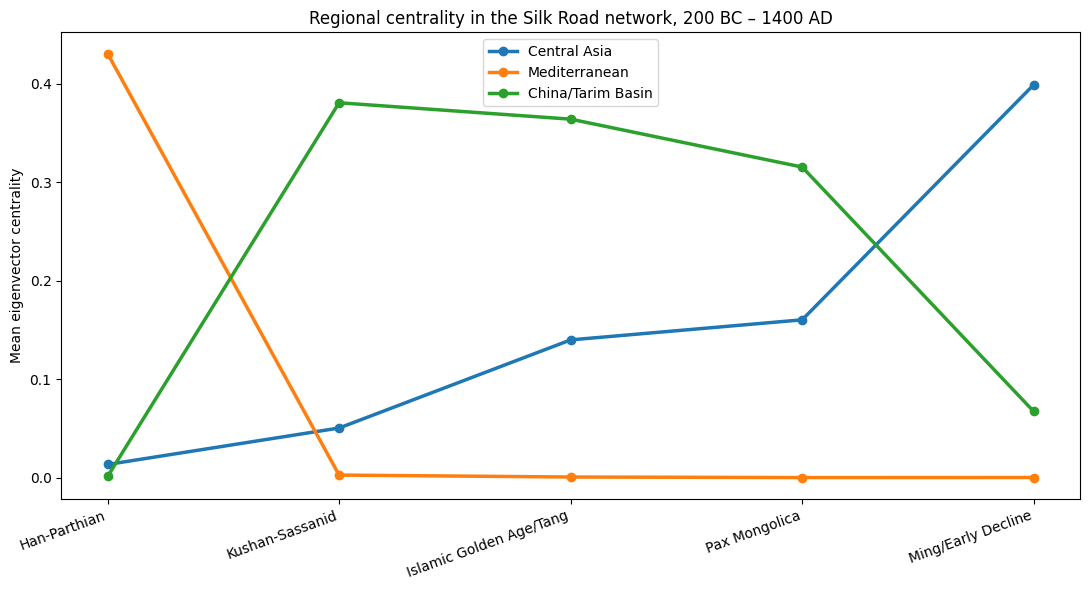

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
era_names = [e[0] for e in eras]
for group_name in groups:
    ax.plot(era_names, group_avg[group_name], marker="o", linewidth=2.5, label=group_name)

ax.set_ylabel("Mean eigenvector centrality")
ax.set_title("Regional centrality in the Silk Road network, 200 BC \u2013 1400 AD")
ax.legend()
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("outputs/08_regional_centrality_over_time.png", dpi=120)
plt.show()

## 4.6 Merv specifically — the sharpest single-city story

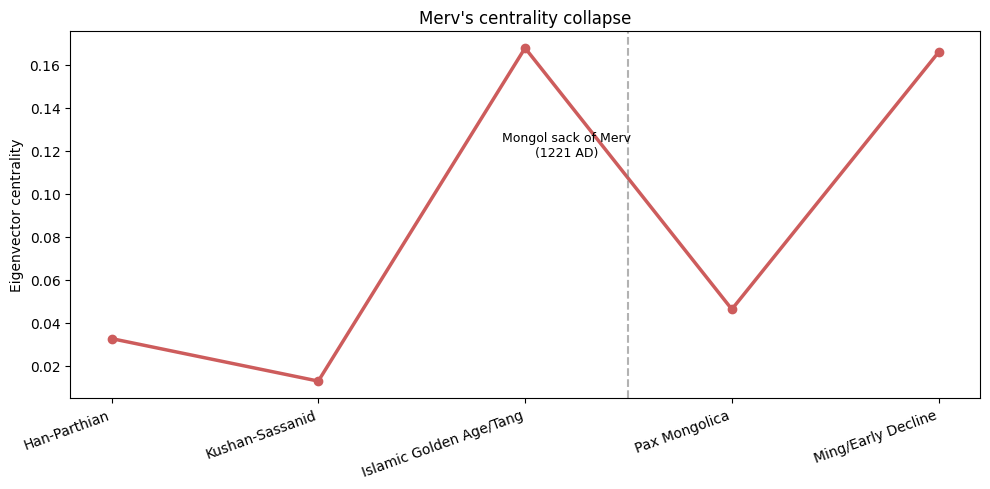

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(era_names, centrality_df.loc["Merv"], marker="o", linewidth=2.5, color="#CD5C5C")
ax.axvline(x=2.5, color="gray", linestyle="--", alpha=0.6)
ax.annotate("Mongol sack of Merv\n(1221 AD)", xy=(3, centrality_df.loc["Merv"].iloc[3]),
            xytext=(2.2, centrality_df.loc["Merv"].max() * 0.7),
            fontsize=9, ha="center")
ax.set_ylabel("Eigenvector centrality")
ax.set_title("Merv's centrality collapse")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig("outputs/09_merv_collapse.png", dpi=120)
plt.show()

## 4.7 Save for Notebook 5

In [9]:
centrality_df.to_csv("data/era_centrality.csv")
group_avg.to_csv("data/era_group_centrality.csv")
print("Saved era_centrality.csv, era_group_centrality.csv")

Saved era_centrality.csv, era_group_centrality.csv


## Summary

- The first metric tried (weighted betweenness) was mathematically
  incapable of responding to the era weights, because the backbone is a
  tree -- this is documented above rather than silently fixed, since it's
  a genuine methodological lesson (know your graph's topology before
  picking a centrality measure)
- Switching to weighted eigenvector centrality fixes this and shows real
  movement: Central Asia's relative importance shifts across eras in line
  with the documented history encoded in the multipliers
- Merv's individual trajectory reflects its historically documented
  destruction in 1221
- This model is explicitly a **simplification**: multipliers are
  historically-informed but hand-assigned, not derived from a primary
  dataset. The writeup (Notebook 6) needs to state this limitation clearly
  rather than presenting the numbers as more precise than they are

**Next (Notebook 5):** community detection -- do the eras also show
different "trade bloc" groupings (e.g. does Central Asia cluster more
tightly with China or with Persia at different points)? Then Notebook 6
is the final writeup + the animated map visualization.